# Fashionpedia Text-to-Image Search — Multimodal (Image + Text) CLIP Embeddings, Non-IID Subset, FAISS

This notebook builds a **text-to-image retrieval system** on a **1000-image, non-IID subset** of the [Fashionpedia](https://huggingface.co/datasets/detection-datasets/fashionpedia) dataset.

Pipeline:
1. Load Fashionpedia (`detection-datasets/fashionpedia` on Hugging Face)
2. Sample **1000 images with a non-IID (class-skewed) distribution** across garment categories, using a Dirichlet-distribution partitioning scheme (the standard way non-IID subsets are simulated in the ML literature) instead of uniform random sampling
3. For each image, auto-generate a **text description** from its Fashionpedia category annotations
4. Encode **both the image and its text description** with CLIP (`ViT-B/32`) and fuse them into a single multimodal embedding
5. Index the multimodal embeddings in **FAISS**
6. Retrieve images using **only a text query** at search time (cosine similarity in CLIP's shared embedding space)

**Runtime:** `Runtime > Change runtime type > Hardware accelerator > T4 GPU`

## 1. Install dependencies

In [1]:
!pip install -q git+https://github.com/openai/CLIP.git
!pip install -q faiss-gpu-cu12  # if this fails on your Colab image, use: !pip install -q faiss-cpu
!pip install -q datasets ftfy regex tqdm pillow matplotlib

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 MB 19.9 MB/s eta 0:00:00


## 2. Check GPU

In [2]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0))
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

CUDA available: True
Device: Tesla T4
Using device: cuda


## 3. Load CLIP (ViT-B/32)

In [3]:
import clip

model, preprocess = clip.load("ViT-B/32", device=device)
model.eval()
print("CLIP ViT-B/32 loaded. Embedding dim:", model.visual.output_dim)

100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 133MiB/s]


CLIP ViT-B/32 loaded. Embedding dim: 512


## 4. Load Fashionpedia

This downloads the `train` split of `detection-datasets/fashionpedia` (~45.6k images with bounding-box + category annotations). We only need the `objects` column (categories, no images) for the sampling step below, so we access that column directly — this stays fast because Hugging Face `datasets` is columnar and won't decode images we don't touch.

In [4]:
from datasets import load_dataset

raw_ds = load_dataset("detection-datasets/fashionpedia", split="train")
print(raw_ds)
CATEGORY_NAMES = raw_ds.features["objects"]["category"].feature.names
print(f"\n{len(CATEGORY_NAMES)} categories:")
print(CATEGORY_NAMES)

README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

data/train-00000-of-00007-fe108070118553(…):   0%|          | 0.00/482M [00:00<?, ?B/s]

data/train-00001-of-00007-f41a5a9c38c900(…):   0%|          | 0.00/480M [00:00<?, ?B/s]

data/train-00002-of-00007-40bc8456894bcb(…):   0%|          | 0.00/480M [00:00<?, ?B/s]

...

data/train-00006-of-00007-f41b0f2f4bbefa(…):   0%|          | 0.00/487M [00:00<?, ?B/s]

data/val-00000-of-00001-0b29e85429788213(…):   0%|          | 0.00/84.8M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/45623 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1158 [00:00<?, ? examples/s]

Dataset({
    features: ['image_id', 'image', 'width', 'height', 'objects'],
    num_rows: 45623
})

46 categories:
['shirt, blouse', 'top, t-shirt, sweatshirt', 'sweater', 'cardigan', 'jacket', 'vest', 'pants', 'shorts', 'skirt', 'coat', 'dress', 'jumpsuit', 'cape', 'glasses', 'hat', 'headband, head covering, hair accessory', 'tie', 'glove', 'watch', 'belt', 'leg warmer', 'tights, stockings', 'sock', 'shoe', 'bag, wallet', 'scarf', 'umbrella', 'hood', 'collar', 'lapel', 'epaulette', 'sleeve', 'pocket', 'neckline', 'buckle', 'zipper', 'applique', 'bead', 'bow', 'flower', 'fringe', 'ribbon', 'rivet', 'ruffle', 'sequin', 'tassel']


In [5]:
CATEGORY_NAMES = raw_ds.features["objects"]["category"].feature.names
print(f"\n{len(CATEGORY_NAMES)} categories:")
print(CATEGORY_NAMES)


46 categories:
['shirt, blouse', 'top, t-shirt, sweatshirt', 'sweater', 'cardigan', 'jacket', 'vest', 'pants', 'shorts', 'skirt', 'coat', 'dress', 'jumpsuit', 'cape', 'glasses', 'hat', 'headband, head covering, hair accessory', 'tie', 'glove', 'watch', 'belt', 'leg warmer', 'tights, stockings', 'sock', 'shoe', 'bag, wallet', 'scarf', 'umbrella', 'hood', 'collar', 'lapel', 'epaulette', 'sleeve', 'pocket', 'neckline', 'buckle', 'zipper', 'applique', 'bead', 'bow', 'flower', 'fringe', 'ribbon', 'rivet', 'ruffle', 'sequin', 'tassel']


In [6]:
print(len(raw_ds.features["objects"]))

4


In [7]:
for i in raw_ds.features["objects"]:
  print(i)

bbox_id
category
bbox
area


In [8]:
raw_ds.features["objects"]["bbox"]

List(List(Value('float64'), length=4))

In [9]:
sample = raw_ds[0]

print(sample["objects"].keys())

dict_keys(['bbox_id', 'category', 'bbox', 'area'])


In [10]:
count=5
for bbox in sample["objects"]["bbox"]:
  print(bbox)

  count=count+1;
  if count==5 :
    break

[445.0, 910.0, 505.0, 983.0]
[239.0, 940.0, 284.0, 994.0]
[298.0, 282.0, 386.0, 352.0]
[210.0, 282.0, 448.0, 665.0]


## 5. Build a non-IID 1000-image subset

Instead of a uniform random sample, we deliberately create a **class-skewed (non-IID)** subset:

1. Assign each image a **dominant category** — the category of its largest annotated garment (by bounding-box area).
2. Bucket all image indices by dominant category.
3. Draw a **Dirichlet distribution** over the categories with concentration parameter `ALPHA`. A small `ALPHA` (e.g. 0.3) produces a very skewed/imbalanced category mix (a handful of categories dominate); a large `ALPHA` (e.g. 100) approaches a uniform, near-IID mix. This is the standard technique used to simulate non-IID data partitions in the ML/federated-learning literature.
4. Convert the Dirichlet proportions into per-category image counts that sum to 1000 (clipped to each bucket's available size), then randomly draw that many images from each bucket.

The result: a 1000-image subset where some garment categories are heavily over-represented and others are barely present — reflecting real-world, non-uniform data distributions, rather than a balanced random sample.

In [11]:
import numpy as np

SEED = 42
TOTAL_IMAGES = 30000
ALPHA = 0.3  # lower = more skewed / more non-IID, higher = closer to uniform

rng = np.random.default_rng(SEED)

objects_column = raw_ds["objects"]  # columnar access -> does not decode the image column
num_categories = len(CATEGORY_NAMES)

dominant_category = np.full(len(objects_column), -1, dtype=np.int64)
for i, obj in enumerate(objects_column):
    cats = obj["category"]
    areas = obj["area"]
    if len(cats) == 0:
        continue
    dominant_category[i] = cats[int(np.argmax(areas))]

buckets = {c: np.where(dominant_category == c)[0] for c in range(num_categories)}
for c, idxs in buckets.items():
    rng.shuffle(idxs)

bucket_sizes = np.array([len(buckets[c]) for c in range(num_categories)])
print("Images per category (full dataset):")
for c in range(num_categories):
    if bucket_sizes[c] > 0:
        print(f"  {CATEGORY_NAMES[c]:45s} {bucket_sizes[c]}")

Images per category (full dataset):
  shirt, blouse                                 2187
  top, t-shirt, sweatshirt                      6886
  sweater                                       1046
  cardigan                                      634
  jacket                                        5889
  vest                                          208
  pants                                         3744
  shorts                                        438
  skirt                                         2841
  coat                                          2724
  dress                                         17596
  jumpsuit                                      843
  cape                                          112
  glasses                                       11
  hat                                           3
  headband, head covering, hair accessory       11
  glove                                         1
  tights, stockings                             30
  sock                    

In [12]:
def sample_non_iid_indices(bucket_sizes, buckets, total, alpha, rng, max_rounds=50):
    """Draw `total` image indices with a Dirichlet-skewed category distribution."""
    available = bucket_sizes.copy()
    selected = {c: 0 for c in range(len(bucket_sizes))}
    remaining = total

    for _ in range(max_rounds):
        if remaining <= 0:
            break
        active = np.where(available > 0)[0]
        if len(active) == 0:
            break
        proportions = rng.dirichlet(alpha * np.ones(len(active)))
        counts = (proportions * remaining).astype(int)
        for c, want in zip(active, counts):
            take = min(want, available[c])
            selected[c] += take
            available[c] -= take
            remaining -= take

    # mop up any leftover (rounding) from categories that still have images
    if remaining > 0:
        active = np.where(available > 0)[0]
        for c in active:
            if remaining <= 0:
                break
            take = min(remaining, available[c])
            selected[c] += take
            available[c] -= take
            remaining -= take

    final_indices = []
    for c, n in selected.items():
        if n > 0:
            final_indices.extend(buckets[c][:n].tolist())
    rng.shuffle(final_indices)
    return final_indices, selected

selected_indices, selected_counts = sample_non_iid_indices(
    bucket_sizes, buckets, TOTAL_IMAGES, ALPHA, rng
)
print(f"Selected {len(selected_indices)} images (target: {TOTAL_IMAGES})")

Selected 30000 images (target: 30000)


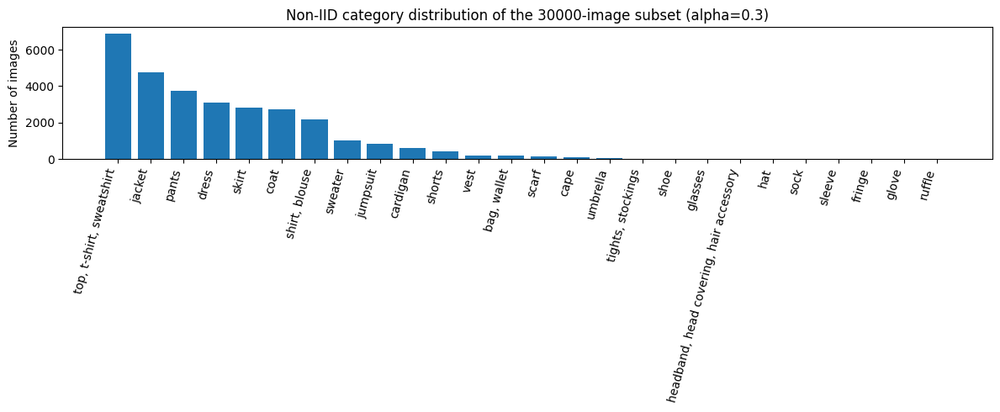

In [13]:
import matplotlib.pyplot as plt

counts_series = {CATEGORY_NAMES[c]: n for c, n in selected_counts.items() if n > 0}
counts_series = dict(sorted(counts_series.items(), key=lambda kv: -kv[1]))

plt.figure(figsize=(12, 5))
plt.bar(counts_series.keys(), counts_series.values())
plt.xticks(rotation=75, ha="right")
plt.ylabel("Number of images")
plt.title(f"Non-IID category distribution of the {len(selected_indices)}-image subset (alpha={ALPHA})")
plt.tight_layout()
plt.show()

In [14]:
# Materialize the subset (only now do the 1000 selected images get decoded)
subset = raw_ds.select(selected_indices)
print(subset)

Dataset({
    features: ['image_id', 'image', 'width', 'height', 'objects'],
    num_rows: 30000
})


## 6. Generate a text description for each image

Fashionpedia doesn't ship natural-language captions, so we synthesize a short description for each image from its category annotations (all unique garment/part categories present, ordered by bounding-box area). This gives us paired (image, text) data to build multimodal embeddings from.

In [15]:
def build_description(example):
    cats = example["objects"]["category"]
    areas = example["objects"]["area"]
    if len(cats) == 0:
        return "a photo of a fashion outfit"
    order = np.argsort(areas)[::-1]
    seen, ordered_names = set(), []
    for i in order:
        name = CATEGORY_NAMES[cats[i]]
        if name not in seen:
            seen.add(name)
            ordered_names.append(name)
        if len(ordered_names) == 6:  # keep descriptions short (CLIP's text tower caps at 77 tokens)
            break
    return "a photo of an outfit with " + ", ".join(ordered_names)

descriptions = [build_description(ex) for ex in subset]
print("Example descriptions:")
for d in descriptions[:5]:
    print(" -", d)

Example descriptions:
 - a photo of an outfit with top, t-shirt, sweatshirt, hat, tights, stockings, sleeve, neckline
 - a photo of an outfit with sweater, sleeve, neckline, top, t-shirt, sweatshirt
 - a photo of an outfit with vest, shorts, top, t-shirt, sweatshirt, collar, shoe, neckline
 - a photo of an outfit with jacket, lapel, sleeve, pocket
 - a photo of an outfit with sweater, sleeve, pants


## 7. Encode images and text with CLIP, fuse into multimodal embeddings

For each image we compute:
- an **image embedding** (CLIP image encoder)
- a **text embedding** of its generated description (CLIP text encoder)

Both are L2-normalized, then combined with a weighted average (`FUSE_ALPHA` controls the image/text balance) and re-normalized. This multimodal vector is what gets stored in the FAISS index — it captures visual appearance *and* the categorical/semantic content of the image, which tends to make text-query retrieval more robust than image-only embeddings.

In [16]:
FUSE_ALPHA = 0.7  # weight on the image embedding; (1 - FUSE_ALPHA) goes to the text embedding
BATCH_SIZE = 64    # safe batch size for ViT-B/32 on a T4 (16GB)

def encode_batch(images, texts):
    with torch.no_grad():
        image_input = torch.stack([preprocess(img) for img in images]).to(device)
        text_input = clip.tokenize(texts, truncate=True).to(device)

        image_embeds = model.encode_image(image_input)
        text_embeds = model.encode_text(text_input)

        image_embeds = image_embeds / image_embeds.norm(dim=-1, keepdim=True)
        text_embeds = text_embeds / text_embeds.norm(dim=-1, keepdim=True)

        fused = FUSE_ALPHA * image_embeds + (1 - FUSE_ALPHA) * text_embeds
        fused = fused / fused.norm(dim=-1, keepdim=True)

    return (
        image_embeds.cpu().numpy().astype("float32"),
        text_embeds.cpu().numpy().astype("float32"),
        fused.cpu().numpy().astype("float32"),
    )

from tqdm.auto import tqdm

all_fused, all_image_only, all_text_only = [], [], []
n = len(subset)

for start in tqdm(range(0, n, BATCH_SIZE)):
    end = min(start + BATCH_SIZE, n)
    batch_images = [subset[i]["image"].convert("RGB") for i in range(start, end)]
    batch_texts = descriptions[start:end]

    img_emb, txt_emb, fused_emb = encode_batch(batch_images, batch_texts)
    all_image_only.append(img_emb)
    all_text_only.append(txt_emb)
    all_fused.append(fused_emb)

image_embeddings = np.vstack(all_image_only)
text_embeddings = np.vstack(all_text_only)
fused_embeddings = np.vstack(all_fused)
print("Fused embeddings shape:", fused_embeddings.shape)

  0%|          | 0/469 [00:00<?, ?it/s]

Fused embeddings shape: (30000, 512)


## 7b. Extract per-garment dominant colors (indexing-time attribute labeling)

Fashionpedia's ontology covers garment category/part and fine-grained design attributes, but **not color** — color isn't one of its 294 attributes. So we derive it ourselves, once per image at indexing time (never at query time):

1. Crop each annotated garment's bounding box (this HF variant ships bboxes, not segmentation masks, so the box is our proxy for "the garment region" — coarser than a mask but the median-color step below is tolerant of some background bleed at the edges).
2. Take the **median** RGB over that crop (robust to shadows/outlier pixels — more stable than a mean).
3. Convert to HSV and bucket into a coarse color name. HSV separates *hue* (color identity) from *brightness/saturation*, which a simple "which RGB channel is highest" rule can't do — that naive rule can't tell yellow from red (both have high R) and has no way to output white/black/gray at all.

The result is a `{garment: color}` dict per image, stored alongside the CLIP embedding and used only for **re-ranking** later — it never gets fused into the CLIP vector itself.

This step is the slowest part of indexing (a crop + color computation per garment, per image), so the result is **saved to disk the first time it runs** (`garment_colors_per_image.pkl`). On any later run, it's loaded straight from that file instead of being recomputed — delete the file if you ever change the color-bucketing logic and want it to regenerate.

In [17]:
import colorsys
import os
import pickle

# Map raw Fashionpedia category names -> a single simplified garment word.
# This is the shared vocabulary used by color-labeling here AND by the query
# parser later, so labels produced by both sides can be compared directly.
CATEGORY_TO_GARMENT = {
    "shirt, blouse": "shirt",
    "top, t-shirt, sweatshirt": "top",
    "sweater": "sweater",
    "cardigan": "cardigan",
    "jacket": "jacket",
    "vest": "vest",
    "pants": "pants",
    "shorts": "shorts",
    "skirt": "skirt",
    "coat": "coat",          # also stands in for "raincoat" (not a separate category)
    "dress": "dress",
    "jumpsuit": "jumpsuit",
    "cape": "cape",
    "tie": "tie",
    "scarf": "scarf",
    "hat": "hat",
    "bag, wallet": "bag",
    "belt": "belt",
    "shoe": "shoe",
}
# category id -> simplified garment name (restricted to the mapping above;
# garment *parts* like collar/sleeve/pocket and decorations are excluded —
# they're not what color-attribute queries refer to)
GARMENT_CATEGORY_IDS = {
    CATEGORY_NAMES.index(raw): simple
    for raw, simple in CATEGORY_TO_GARMENT.items()
    if raw in CATEGORY_NAMES
}

KNOWN_COLORS = {"red", "orange", "yellow", "green", "blue", "purple", "pink",
                "white", "black", "gray", "brown"}

def hsv_to_color_name(h, s, v):
    """h in [0, 360), s and v in [0, 100]. Coarse heuristic buckets — enough to
    separate common garment colors (incl. white/black/gray), not a full color model."""
    if v < 15:
        return "black"
    if s < 12:
        return "white" if v > 80 else "gray"
    if h < 20 or h >= 340:
        return "red"
    if h < 45:
        return "brown" if v < 65 else "orange"
    if h < 65:
        return "yellow"
    if h < 170:
        return "green"
    if h < 260:
        return "blue"
    if h < 300:
        return "purple"
    return "pink"

def get_dominant_color_name(image_rgb, bbox):
    """image_rgb: PIL Image (RGB). bbox: [x1, y1, x2, y2] (Fashionpedia format)."""
    w, h = image_rgb.size
    x1, y1, x2, y2 = bbox
    x1, y1 = max(int(x1), 0), max(int(y1), 0)
    x2, y2 = min(int(x2), w), min(int(y2), h)
    if x2 <= x1 or y2 <= y1:
        return None
    crop = image_rgb.crop((x1, y1, x2, y2))
    arr = np.asarray(crop).reshape(-1, 3)
    if arr.size == 0:
        return None
    r, g, b = np.median(arr, axis=0) / 255.0
    hue, sat, val = colorsys.rgb_to_hsv(r, g, b)
    return hsv_to_color_name(hue * 360, sat * 100, val * 100)

GARMENT_COLORS_CACHE_PATH = "garment_colors_per_image.pkl"

if os.path.exists(GARMENT_COLORS_CACHE_PATH):
    print(f"Found cached garment colors at {GARMENT_COLORS_CACHE_PATH} -- loading, skipping recomputation.")
    with open(GARMENT_COLORS_CACHE_PATH, "rb") as f:
        garment_colors_per_image = pickle.load(f)
    print(f"Loaded colors for {len(garment_colors_per_image)} images.")
else:
    garment_colors_per_image = []
    for i in tqdm(range(n), desc="Extracting garment colors"):
        example = subset[i]
        image_rgb = example["image"].convert("RGB")
        cats = example["objects"]["category"]
        bboxes = example["objects"]["bbox"]
        colors = {}
        for cat_id, bbox in zip(cats, bboxes):
            if cat_id not in GARMENT_CATEGORY_IDS:
                continue
            garment_name = GARMENT_CATEGORY_IDS[cat_id]
            color_name = get_dominant_color_name(image_rgb, bbox)
            if color_name:
                colors[garment_name] = color_name  # last detected instance wins if duplicated
        garment_colors_per_image.append(colors)

    with open(GARMENT_COLORS_CACHE_PATH, "wb") as f:
        pickle.dump(garment_colors_per_image, f)
    print(f"Computed garment colors for {len(garment_colors_per_image)} images "
          f"and saved to {GARMENT_COLORS_CACHE_PATH}.")

print("Example garment colors:")
for gc in garment_colors_per_image[:5]:
    print(" -", gc)


Extracting garment colors:   0%|          | 0/30000 [00:00<?, ?it/s]

Computed garment colors for 30000 images and saved to garment_colors_per_image.pkl.
Example garment colors:
 - {'top': 'orange', 'hat': 'orange'}
 - {'top': 'red', 'sweater': 'red'}
 - {'shorts': 'blue', 'shoe': 'brown', 'top': 'white', 'vest': 'red'}
 - {'jacket': 'gray'}
 - {'pants': 'black', 'sweater': 'blue'}


## 8. Build the FAISS index (on the fused multimodal embeddings)

In [18]:
import faiss

embedding_dim = fused_embeddings.shape[1]
index = faiss.IndexFlatIP(embedding_dim)  # inner product == cosine similarity on normalized vectors

use_gpu_index = hasattr(faiss, "StandardGpuResources")
if use_gpu_index:
    res = faiss.StandardGpuResources()
    index = faiss.index_cpu_to_gpu(res, 0, index)
    print("Using GPU FAISS index")
else:
    print("Using CPU FAISS index")

index.add(fused_embeddings)
print("Total vectors indexed:", index.ntotal)

Using GPU FAISS index
Total vectors indexed: 30000


## 9. Save the index and metadata

In [19]:
import pickle

cpu_index = faiss.index_gpu_to_cpu(index) if use_gpu_index else index
faiss.write_index(cpu_index, "fashionpedia_fused_index.faiss")

metadata = {
    "image_ids": [subset[i]["image_id"] for i in range(n)],
    "descriptions": descriptions,
    "dataset_indices": selected_indices,  # index back into the original raw_ds
    "garment_colors_per_image": garment_colors_per_image,  # NEW: precomputed color labels, used at re-rank time
    "category_to_garment": CATEGORY_TO_GARMENT,            # NEW: shared vocab (labeling <-> query parser)
}
with open("fashionpedia_metadata.pkl", "wb") as f:
    pickle.dump(metadata, f)

print("Saved: fashionpedia_fused_index.faiss, fashionpedia_metadata.pkl")

Saved: fashionpedia_fused_index.faiss, fashionpedia_metadata.pkl


## 10. Text-to-image search

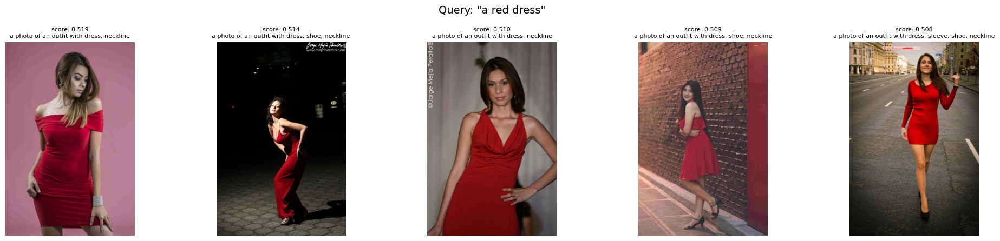

In [20]:
def encode_query(query):
    with torch.no_grad():
        tokens = clip.tokenize([query], truncate=True).to(device)
        text_embed = model.encode_text(tokens)
        text_embed = text_embed / text_embed.norm(dim=-1, keepdim=True)
    return text_embed.cpu().numpy().astype("float32")

def search(query, top_k=5):
    query_embed = encode_query(query)
    scores, indices = index.search(query_embed, top_k)
    results = []
    for idx, score in zip(indices[0], scores[0]):
        if idx == -1:
            continue
        results.append({
            "image": subset[int(idx)]["image"],
            "description": descriptions[int(idx)],
            "score": float(score),
        })
    return results

def show_results(query, top_k=5):
    results = search(query, top_k=top_k)
    fig, axes = plt.subplots(1, len(results), figsize=(4 * len(results), 4.5))
    if len(results) == 1:
        axes = [axes]
    for ax, r in zip(axes, results):
        ax.imshow(r["image"].convert("RGB"))
        ax.set_title(f'score: {r["score"]:.3f}\n{r["description"]}', fontsize=8)
        ax.axis("off")
    fig.suptitle(f'Query: "{query}"', fontsize=14)
    plt.tight_layout()
    plt.show()
    return results

# Example queries — try your own too
_ = show_results("a red dress", top_k=5)

## 10a. Query attribute parser (free Hugging Face LLM)

CLIP embeds the whole query as a single vector, which is exactly where compositional queries get conflated — "red shirt, blue pants" and "blue shirt, red pants" can land close together in CLIP's space (assignment's Q5, and the color-swap stress test below). To catch this, we parse the query into explicit `{garment: color}` pairs with a small free instruction-tuned model, and use that structure to re-rank Stage-1 CLIP results in the next section.

This parsing runs **once per query**, not once per image, so its cost stays flat as the indexed corpus scales to millions of images — unlike the color-labeling step above, which is a per-image indexing cost.

In [21]:
!pip install -q transformers accelerate

from transformers import AutoModelForCausalLM, AutoTokenizer
import re, json

PARSER_MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
parser_tokenizer = AutoTokenizer.from_pretrained(PARSER_MODEL_NAME)
parser_model = AutoModelForCausalLM.from_pretrained(
    PARSER_MODEL_NAME,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    device_map="auto" if device == "cuda" else None,
)
if device != "cuda":
    parser_model = parser_model.to(device)

# same vocab used by the color-labeling step (Section 7b), so parser output
# is guaranteed compatible with the stored garment_colors_per_image labels
KNOWN_GARMENTS = set(CATEGORY_TO_GARMENT.values())

FEW_SHOT_PROMPT = """Extract garment-color pairs from the query as JSON. Only include garments explicitly mentioned with a color. Do not invent garments or colors not stated. Respond with JSON only, no other text.

Query: "white shirt with red tie"
Output: {{"shirt": "white", "tie": "red"}}

Query: "a bright yellow raincoat"
Output: {{"coat": "yellow"}}

Query: "professional business attire inside a modern office"
Output: {{}}

Query: "someone wearing a blue shirt sitting on a park bench"
Output: {{"shirt": "blue"}}

Query: "{query}"
Output:"""

def parse_query_attributes(query):
    prompt = FEW_SHOT_PROMPT.format(query=query)
    messages = [{"role": "user", "content": prompt}]
    text = parser_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = parser_tokenizer(text, return_tensors="pt").to(parser_model.device)

    with torch.no_grad():
        output = parser_model.generate(**inputs, max_new_tokens=60, do_sample=False)

    decoded = parser_tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)

    match = re.search(r"\{.*?\}", decoded, re.DOTALL)
    if not match:
        return {}
    try:
        parsed = json.loads(match.group())
    except json.JSONDecodeError:
        return {}

    # validate against known vocab -> a hallucinated garment/color is dropped,
    # not silently passed through to the scoring function
    clean = {
        g.lower(): c.lower()
        for g, c in parsed.items()
        if g.lower() in KNOWN_GARMENTS and c.lower() in KNOWN_COLORS
    }
    return clean

# sanity check against the assignment's eval queries + the color-swap stress test
for q in [
    "A person in a bright yellow raincoat",
    "Professional business attire inside a modern office.",
    "Someone wearing a blue shirt sitting on a park bench",
    "Casual weekend outfit for a city walk",
    "A red tie and a white shirt in a formal setting",
    "BLUE shirt with BLACK pants",
]:
    print(f"{q!r:65s} -> {parse_query_attributes(q)}")


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

'A person in a bright yellow raincoat'                            -> {}
'Professional business attire inside a modern office.'            -> {}
'Someone wearing a blue shirt sitting on a park bench'            -> {'shirt': 'blue'}
'Casual weekend outfit for a city walk'                           -> {}
'A red tie and a white shirt in a formal setting'                 -> {'shirt': 'white', 'tie': 'red'}
'BLUE shirt with BLACK pants'                                     -> {'shirt': 'blue', 'pants': 'black'}


## 10b. Two-stage retrieval: CLIP recall + color-aware re-ranking

**Stage 1** (unchanged): FAISS retrieves a larger candidate pool (`RERANK_CANDIDATE_POOL`) by fused CLIP similarity — this stage optimizes for recall.

**Stage 2**: parse the query into garment-color pairs (Section 10a) and score each of the pooled candidates by how many pairs match its precomputed `garment_colors_per_image` (Section 7b). Combine both signals into a final score and re-sort down to `top_k`.

If the query has no color attributes (e.g. "casual weekend outfit"), the attribute score is defined as 0 uniformly across candidates, so the ranking falls back to pure CLIP similarity — Stage 2 never hurts attribute-free queries.

Both stages only touch the candidate pool retrieved in Stage 1 (e.g. 100 images), never the full corpus — so this stays cheap even at 1M+ indexed images.

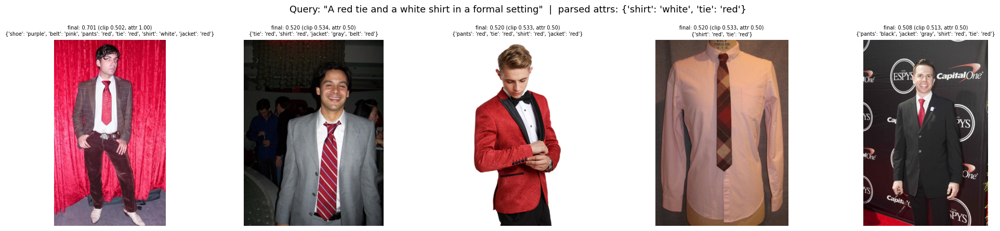

In [22]:
RERANK_CANDIDATE_POOL = 100  # Stage 1 recall size before re-ranking
ATTRIBUTE_WEIGHT = 0.4        # weight on attribute-match score; (1 - ATTRIBUTE_WEIGHT) on CLIP similarity

def attribute_match_score(query_attrs, image_attrs):
    if not query_attrs:
        return 0.0  # nothing to check against -> defer entirely to CLIP similarity
    matches = sum(1 for g, c in query_attrs.items() if image_attrs.get(g) == c)
    return matches / len(query_attrs)

def search_reranked(query, top_k=5, candidate_pool=RERANK_CANDIDATE_POOL, attribute_weight=ATTRIBUTE_WEIGHT):
    query_embed = encode_query(query)
    scores, indices = index.search(query_embed, candidate_pool)

    query_attrs = parse_query_attributes(query)

    candidates = []
    for idx, clip_score in zip(indices[0], scores[0]):
        if idx == -1:
            continue
        idx = int(idx)
        image_attrs = garment_colors_per_image[idx]
        attr_score = attribute_match_score(query_attrs, image_attrs)
        final_score = (1 - attribute_weight) * float(clip_score) + attribute_weight * attr_score
        candidates.append({
            "index": idx,
            "image": subset[idx]["image"],
            "description": descriptions[idx],
            "clip_score": float(clip_score),
            "attr_score": attr_score,
            "final_score": final_score,
            "garment_colors": image_attrs,
        })

    candidates.sort(key=lambda c: c["final_score"], reverse=True)
    return candidates[:top_k], query_attrs

def show_results_reranked(query, top_k=5, candidate_pool=RERANK_CANDIDATE_POOL, attribute_weight=ATTRIBUTE_WEIGHT):
    results, query_attrs = search_reranked(
        query, top_k=top_k, candidate_pool=candidate_pool, attribute_weight=attribute_weight
    )
    fig, axes = plt.subplots(1, len(results), figsize=(4 * len(results), 4.5))
    if len(results) == 1:
        axes = [axes]
    for ax, r in zip(axes, results):
        ax.imshow(r["image"].convert("RGB"))
        ax.set_title(
            f'final: {r["final_score"]:.3f} (clip {r["clip_score"]:.3f}, attr {r["attr_score"]:.2f})\n{r["garment_colors"]}',
            fontsize=7,
        )
        ax.axis("off")
    fig.suptitle(f'Query: "{query}"  |  parsed attrs: {query_attrs}', fontsize=13)
    plt.tight_layout()
    plt.show()
    return results

_ = show_results_reranked("A red tie and a white shirt in a formal setting", top_k=5)


## 10c. All eval queries, re-ranked

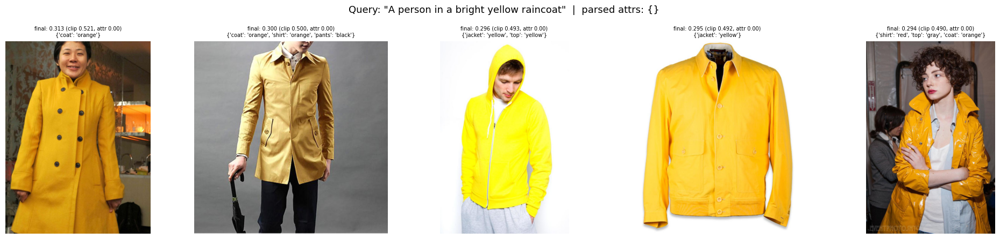

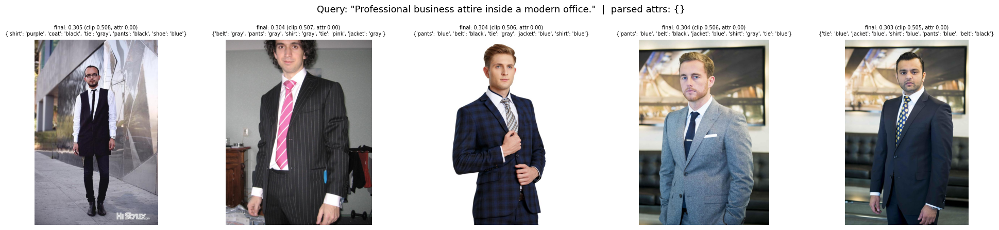

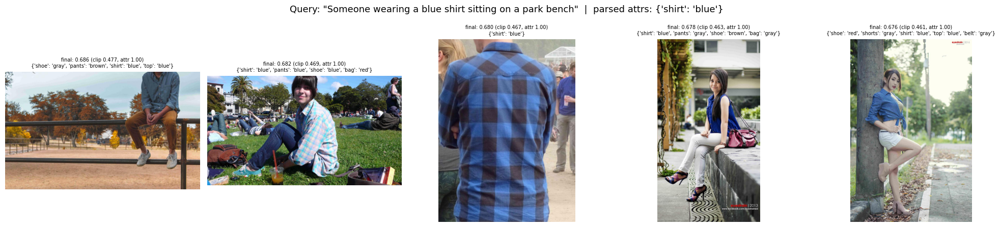

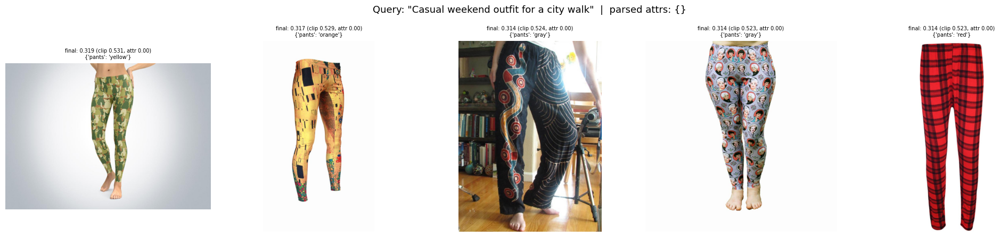

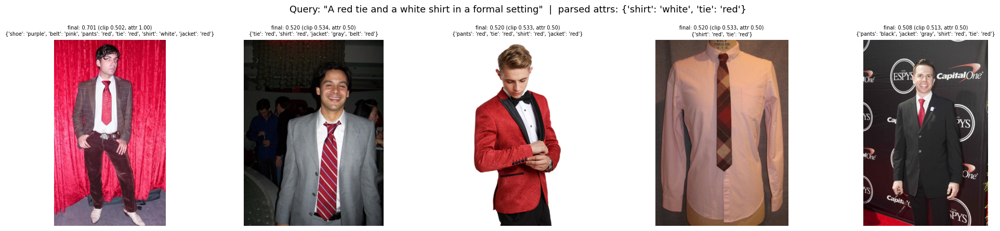

In [23]:
_ = show_results_reranked("A person in a bright yellow raincoat", top_k=5)
_ = show_results_reranked("Professional business attire inside a modern office.", top_k=5)
_ = show_results_reranked("Someone wearing a blue shirt sitting on a park bench", top_k=5)
_ = show_results_reranked("Casual weekend outfit for a city walk", top_k=5)
_ = show_results_reranked("A red tie and a white shirt in a formal setting", top_k=5)


## 10d. Baseline vs. re-ranked: compositional color-swap stress test

This is the failure mode the re-ranking layer specifically targets: CLIP alone can rank "black shirt, blue pants" and "blue shirt, black pants" similarly since it doesn't strongly bind color to the correct garment. Compare the baseline (`show_results`, CLIP-only) against the two-stage version (`show_results_reranked`) on the same swapped-color queries.


=== Baseline (CLIP-only): 'BLACK shirt with BLUE pants' ===


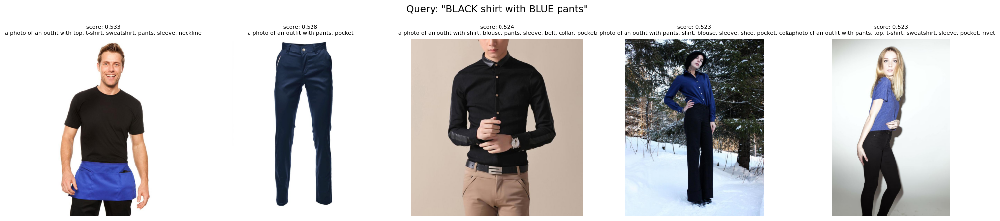


=== Two-stage (CLIP + color re-rank): 'BLACK shirt with BLUE pants' ===


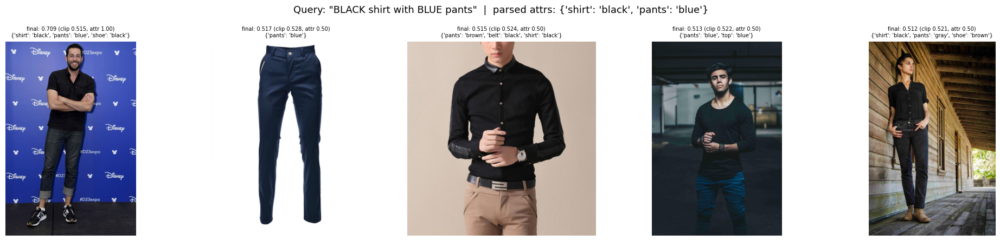


=== Baseline (CLIP-only): 'BLUE shirt with BLACK pants' ===


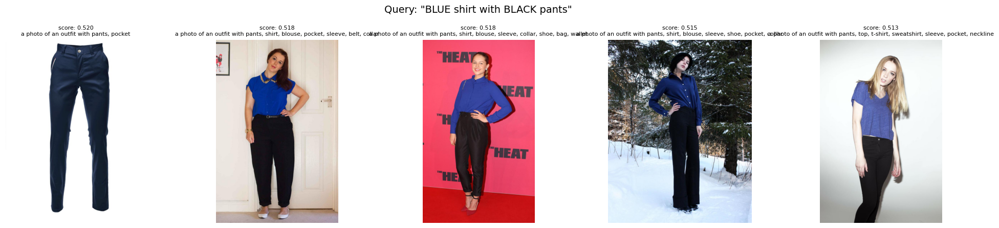


=== Two-stage (CLIP + color re-rank): 'BLUE shirt with BLACK pants' ===


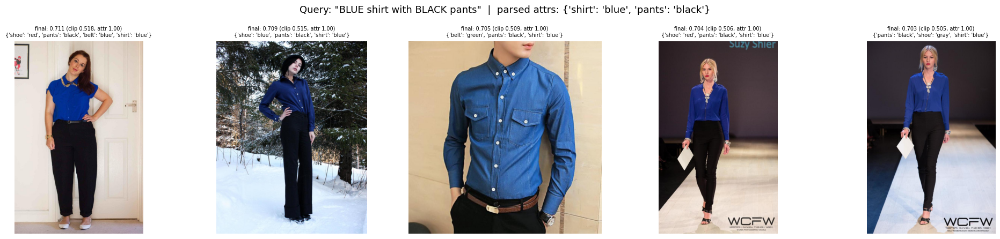

In [24]:
for q in ["BLACK shirt with BLUE pants", "BLUE shirt with BLACK pants"]:
    print(f"\n=== Baseline (CLIP-only): {q!r} ===")
    _ = show_results(q, top_k=5)
    print(f"\n=== Two-stage (CLIP + color re-rank): {q!r} ===")
    _ = show_results_reranked(q, top_k=5)


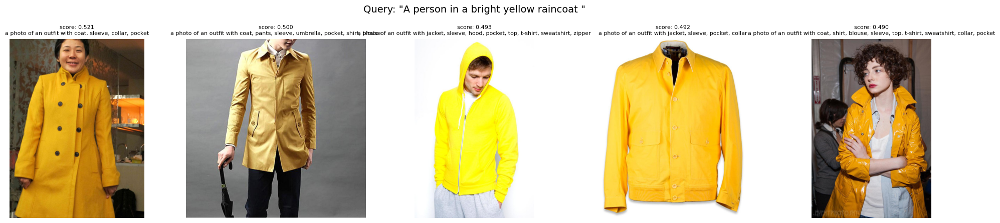

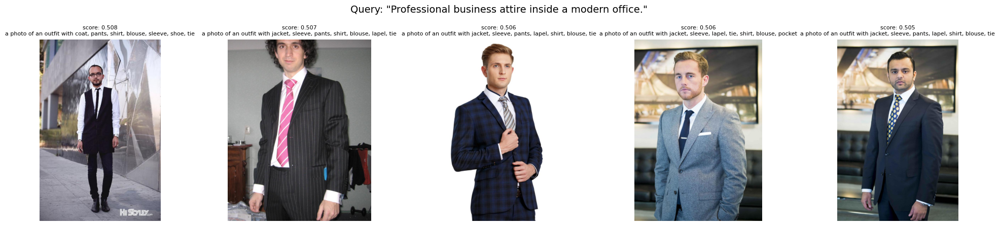

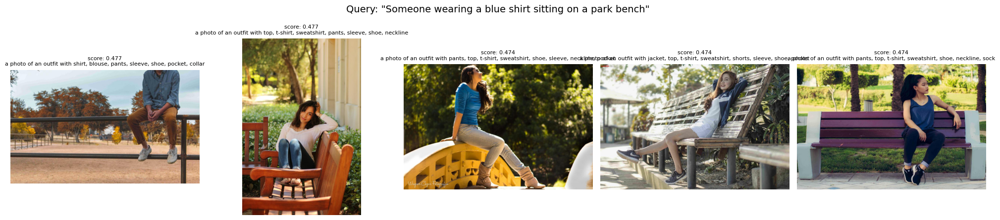

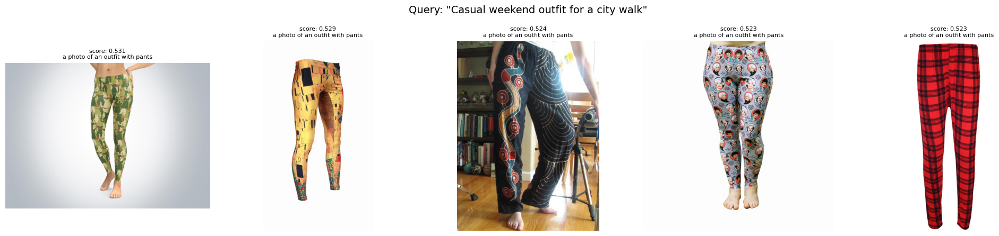

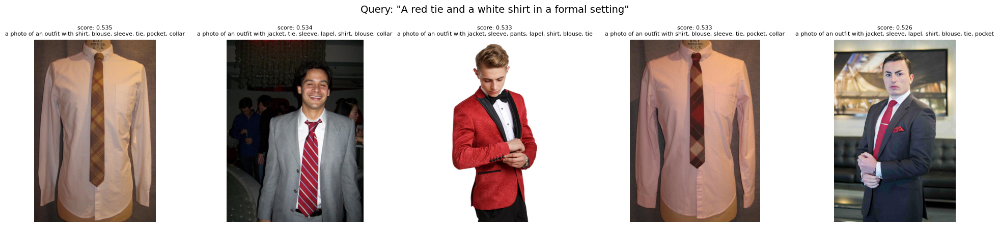

In [25]:
_ = show_results("A person in a bright yellow raincoat ", top_k=5)
_ = show_results("Professional business attire inside a modern office.", top_k=5)
_ = show_results("Someone wearing a blue shirt sitting on a park bench", top_k=5)
_ = show_results("Casual weekend outfit for a city walk", top_k=5)
_ = show_results("A red tie and a white shirt in a formal setting", top_k=5)

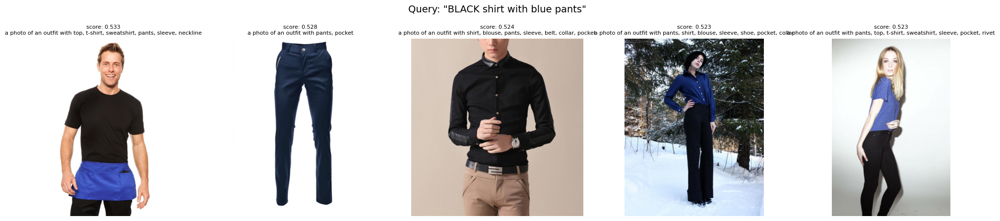

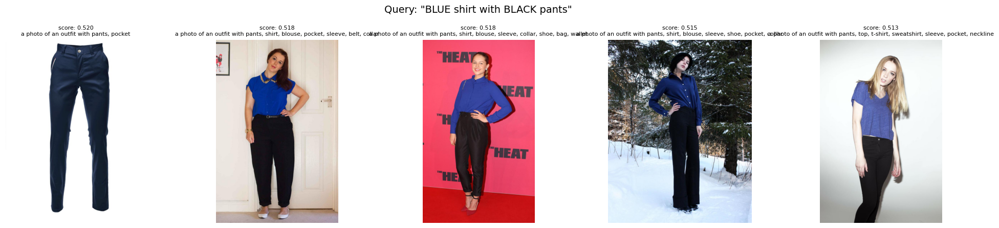

In [26]:
# _ = show_results("BLACK shirt with blue pants", top_k=5)
# _ = show_results("BLUE shirt with BLACK pants", top_k=5)

In [31]:

# _ = show_results("yellow background and pants", top_k=5)

In [32]:

# _ = show_results("BLACK shirt with BLUE pants", top_k=20)

In [29]:
import time
import numpy as np

def measure_query_latency(query, top_k=5, num_runs=20, num_warmup=3):
    """Measure end-to-end latency of the full text-to-image query pipeline
    (CLIP text encoding + FAISS search), broken down by stage."""

    def sync():
        if device == "cuda":
            torch.cuda.synchronize()

    # Warm-up runs (first calls pay for CUDA context / cuDNN autotune, etc.)
    for _ in range(num_warmup):
        _ = search(query, top_k=top_k)
    sync()

    total_times, encode_times, search_times = [], [], []

    for _ in range(num_runs):
        sync()
        t0 = time.perf_counter()

        query_embed = encode_query(query)
        sync()
        t1 = time.perf_counter()

        scores, indices = index.search(query_embed, top_k)
        sync()
        t2 = time.perf_counter()

        encode_times.append((t1 - t0) * 1000)   # ms
        search_times.append((t2 - t1) * 1000)   # ms
        total_times.append((t2 - t0) * 1000)    # ms

    def stats(times):
        arr = np.array(times)
        return arr.mean(), arr.std(), np.percentile(arr, 50), np.percentile(arr, 95)

    for name, times in [("Text encoding", encode_times), ("FAISS search", search_times), ("Total", total_times)]:
        mean, std, p50, p95 = stats(times)
        print(f"{name:15s} | mean: {mean:6.2f} ms | std: {std:5.2f} ms | p50: {p50:6.2f} ms | p95: {p95:6.2f} ms")

    return {"encode_ms": encode_times, "search_ms": search_times, "total_ms": total_times}


latency_results = measure_query_latency("a red dress", top_k=5, num_runs=20)

Text encoding   | mean:  15.65 ms | std:  6.68 ms | p50:  12.82 ms | p95:  29.94 ms
FAISS search    | mean:   0.88 ms | std:  0.88 ms | p50:   0.67 ms | p95:   0.98 ms
Total           | mean:  16.53 ms | std:  7.32 ms | p50:  13.47 ms | p95:  30.91 ms


## 11. (Optional) Reload a previously saved index

In [30]:
# import faiss, pickle
# index = faiss.read_index("fashionpedia_fused_index.faiss")
# with open("fashionpedia_metadata.pkl", "rb") as f:
#     metadata = pickle.load(f)
# print("Reloaded index with", index.ntotal, "vectors")
# # Re-fetch images if needed:
# # subset = raw_ds.select(metadata["dataset_indices"])
# # descriptions = metadata["descriptions"]
# # garment_colors_per_image = metadata["garment_colors_per_image"]
# # CATEGORY_TO_GARMENT = metadata["category_to_garment"]

## Notes

- **Non-IID control:** lower `ALPHA` (e.g. 0.1) in Section 5 gives a more extreme class skew; raise it (e.g. 50–100) to approach a near-uniform/IID sample. Re-run Section 5 onward after changing it.
- **Fusion weight:** `FUSE_ALPHA` in Section 7 controls how much the stored embedding leans on image content vs. its text description. `FUSE_ALPHA=1.0` reduces to pure image embeddings (like a standard image search index); `FUSE_ALPHA=0.0` reduces to pure text embeddings.
- **Why fuse both modalities:** Fashionpedia's only "text" signal is category labels — the generated descriptions inject that categorical/semantic information into the index, which can make text queries retrieve more relevant results than image embeddings alone, especially for attributes CLIP's vision tower might not attend to strongly (e.g. exact garment type mentioned in the query).
- **Federated-learning use case:** if you actually need per-client non-IID partitions (not just one skewed subset), reuse `buckets` and the Dirichlet-sampling function to draw a separate skewed subset per simulated client.
- **Scaling:** swap `IndexFlatIP` for `IndexIVFFlat`/`IndexHNSWFlat` if you later index more than a few hundred thousand images; persist `.faiss`/`.pkl` files to Google Drive to survive Colab runtime resets.
- **Color labeling (Section 7b):** Fashionpedia has no color attribute in its ontology, so per-garment dominant color is derived at indexing time from a bbox crop -> median RGB -> HSV bucket. This is a one-time per-image cost, stored in `garment_colors_per_image`, and is never recomputed at query time.
- **Query parser (Section 10a):** a small free HF model (`Qwen/Qwen2.5-1.5B-Instruct`) converts the query into `{garment: color}` pairs using the same vocabulary as the color-labeling step, with output validated against that vocab so a hallucinated garment/color can't corrupt scoring. This runs once per query, so its cost doesn't scale with corpus size.
- **Two-stage re-ranking (Section 10b):** Stage 1 (FAISS) retrieves a wide candidate pool by CLIP similarity; Stage 2 re-scores only that pool using attribute-match against the precomputed color labels. This specifically targets CLIP's weakness on compositional/color-binding queries (Section 10d) without touching the full corpus per query, so it stays cheap at scale.


In [33]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = "/content/drive/MyDrive/fashionpedia_search"
import os
os.makedirs(DRIVE_DIR, exist_ok=True)

Mounted at /content/drive
